# Decision Tree- Claimants prediction

### 1. Business Undestanding

In [20]:
#output
# Claimants hire an attornoy or not 
# understand which type of customers are more likely to do 


### 2. Data Collection

#### 2.1. Import nesessary library and dataset

In [1]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import pickle

claimants_data =pd.read_csv(r'C:\Users\Senthil\Desktop\Data Science\jupyter\ML\2.Logistic Regression\claimants.csv')

### 3. Data Understanding

#### 3.1 perform Initial investigation on the data

In [22]:
# shape 
claimants_data.shape
print(claimants_data.shape)


# Null check
claimants_data.isna().sum()
print(claimants_data.isna().sum())

# data types
claimants_data.dtypes
print(claimants_data.dtypes)

(1340, 7)
CASENUM       0
ATTORNEY      0
CLMSEX       12
CLMINSUR     41
SEATBELT     48
CLMAGE      189
LOSS          0
dtype: int64
CASENUM       int64
ATTORNEY      int64
CLMSEX      float64
CLMINSUR    float64
SEATBELT    float64
CLMAGE      float64
LOSS        float64
dtype: object


### 4. Data preparation

#### 4.1 Data Cleaning

In [23]:
claimants_data.dropna(inplace = True)

In [24]:
# duplicates check 
claimants_data.duplicated().unique()
print(claimants_data.duplicated().unique()) 

# describe
claimants_data.describe()

[False]


,CASENUM,ATTORNEY,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
count,1096.000000,1096.000000,1096.000000,1096.000000,1096.000000,1096.000000,1096.000000
mean,11244.278285,0.472628,0.564781,0.904197,0.018248,28.587591,3.856578
std,9425.386224,0.499478,0.496012,0.294455,0.133909,20.392621,10.473239
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4502.750000,0.000000,0.000000,1.000000,0.000000,9.000000,0.440000
50%,8730.500000,0.000000,1.000000,1.000000,0.000000,30.000000,1.311000
75%,16013.000000,1.000000,1.000000,1.000000,0.000000,43.000000,3.910500
max,34153.000000,1.000000,1.000000,1.000000,1.000000,95.000000,173.604000


#### 4.2 Input and output features

In [25]:
x = claimants_data.iloc[:,2:] #input features 
x

,CLMSEX,CLMINSUR,SEATBELT,CLMAGE,LOSS
0,0.0,1.0,0.0,50.0,34.940
1,1.0,0.0,0.0,18.0,0.891
2,0.0,1.0,0.0,5.0,0.330
3,0.0,1.0,1.0,31.0,0.037
4,0.0,1.0,0.0,30.0,0.038
...,...,...,...,...,...
1334,1.0,1.0,0.0,16.0,0.060
1336,1.0,1.0,0.0,46.0,3.705
1337,1.0,1.0,0.0,39.0,0.099
1338,1.0,0.0,0.0,8.0,3.177


In [26]:
claimants_data.iloc[:,1]

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

In [27]:
y = claimants_data['ATTORNEY']
y

0       0
1       1
2       1
3       0
4       1
       ..
1334    1
1336    0
1337    1
1338    0
1339    1
Name: ATTORNEY, Length: 1096, dtype: int64

### 5. Model Building

In [28]:
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.20,
                                                    shuffle=True,random_state=39)

In [61]:
dt_model = DecisionTreeClassifier(max_depth=5)

In [62]:
dt_model1 = DecisionTreeClassifier()# for gridsearch cv -> dtmodel1

### 6. Model training

#### Grid search CV(Cross validation)

In [63]:
from sklearn.model_selection import GridSearchCV

In [64]:
gridsearch = GridSearchCV(estimator = dt_model1,param_grid= {"max_depth":[5,6,7,8,9,10],
                                                           "criterion":['gini','entropy']})
gridsearch.fit(x,y)

print(gridsearch.best_params_)
print(gridsearch.best_score_)

{'criterion': 'gini', 'max_depth': 5}
0.7253507679535076


In [65]:
gridsearch = GridSearchCV(estimator = dt_model1, param_grid= {"max_depth":[5,6,7,8,9,10],
                                                           "criterion":['gini','entropy']})
gridsearch.fit(X_train,y_train)

print(gridsearch.best_params_)
print(gridsearch.best_score_)

{'criterion': 'gini', 'max_depth': 5}
0.6861363636363637


In [66]:
gridsearch = GridSearchCV(estimator = dt_model1, param_grid= {"max_depth":[5,6,7,8,9,10],
                                                           "criterion":['gini','entropy']})
gridsearch.fit(X_test,y_test)

print(gridsearch.best_params_)
print(gridsearch.best_score_)

{'criterion': 'entropy', 'max_depth': 5}
0.7227272727272728


In [67]:
dt_model.fit(X_train,y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


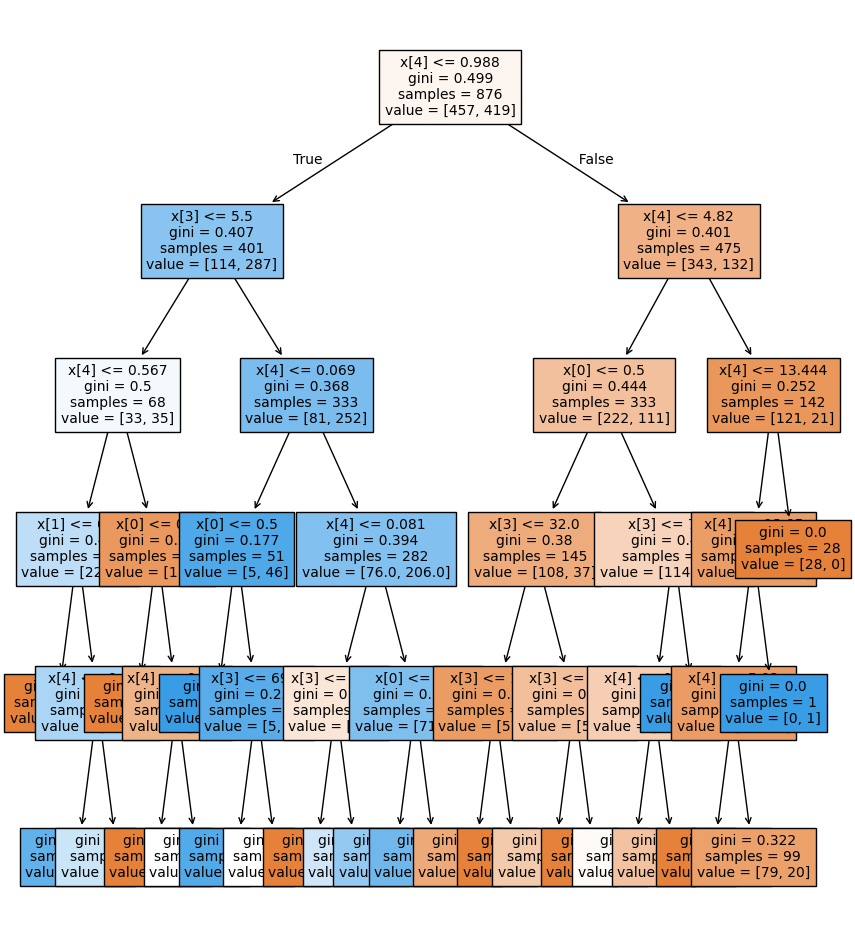

In [68]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure( figsize = (10, 12))
plot_tree(dt_model,fontsize= 10,filled=True)
plt.show()

### 7. Model testing

##### Training data

In [69]:
y_pred_train = dt_model.predict(X_train)

##### Testing data

In [70]:
y_pred_test = dt_model.predict(X_test)

### 8. Model Evaluation

In [71]:
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,roc_curve,roc_auc_score

##### 8.1 Evaluation metrics for Training data

In [72]:
print(confusion_matrix(y_train,y_pred_train))

[[360  97]
 [130 289]]


In [73]:
print(classification_report(y_train,y_pred_train))

              precision    recall  f1-score   support

           0       0.73      0.79      0.76       457
           1       0.75      0.69      0.72       419

    accuracy                           0.74       876
   macro avg       0.74      0.74      0.74       876
weighted avg       0.74      0.74      0.74       876



In [74]:
accuracy_score(y_train,y_pred_train)

0.7408675799086758

##### ROC Curve - Receiver Operating Characteristics
AUC - Area Under this Curve

0.7387418204227006


Text(0, 0.5, 'True Positive Rate')

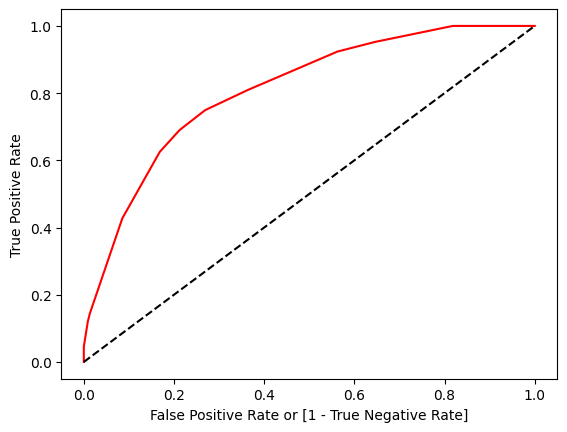

In [75]:
fpr, tpr, thresholds = roc_curve(y_train, dt_model.predict_proba (X_train)[:,1])

auc = roc_auc_score(y_train,y_pred_train)
print(auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

##### 8.2 Evaluation metrics for  Test data

In [76]:
print(confusion_matrix(y_test,y_pred_test))

[[99 22]
 [32 67]]


In [77]:
print(classification_report(y_test,y_pred_test))

              precision    recall  f1-score   support

           0       0.76      0.82      0.79       121
           1       0.75      0.68      0.71        99

    accuracy                           0.75       220
   macro avg       0.75      0.75      0.75       220
weighted avg       0.75      0.75      0.75       220



In [78]:
accuracy_score(y_test,y_pred_test)

0.7545454545454545

##### ROC Curve - Receiver Operating Characteristics
AUC - Area Under this Curve

AUC: 0.7474747474747475


Text(0, 0.5, 'True Positive Rate')

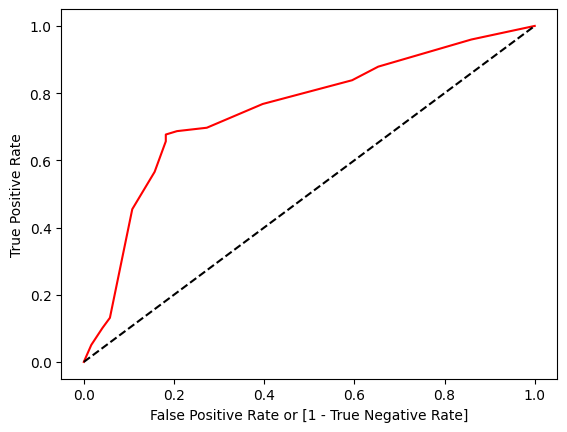

In [79]:
fpr, tpr, thresholds = roc_curve(y_test, dt_model.predict_proba(X_test)[:,1])

auc = roc_auc_score(y_test,y_pred_test)
print("AUC:",auc)

import matplotlib.pyplot as plt
plt.plot(fpr, tpr, color='red', label='logit model ( area  = %0.2f)'%auc)
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate or [1 - True Negative Rate]')
plt.ylabel('True Positive Rate')

### 9. Model Deployment

In [80]:
pickle.dump(obj = dt_model,file = open(file = 'DT_intelligence_file.pkl',mode = 'wb'))

In [81]:
dt_intel_pkl = pickle.load(file = open(file = 'DT_intelligence_file.pkl',mode = 'rb'))

In [82]:
dt_intel_pkl.predict(X_test)

array([0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0,
       1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 0, 0,
       1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 0,
       0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1,
       0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0,
       1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1,
       0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 0])